In [1]:
import pandas as pd 

df = pd.read_csv("covid19.csv")
df = df.fillna(0)
df['Date_reported'] = pd.to_datetime(df['Date_reported'])
df

,Date_reported,Country_code,Country,Continent,WHO_region,New_cases,Cumulative_cases,New_deaths,Cumulative_deaths
0,2020-01-05,AF,Afghanistan,Asia,EMRO,0.0,0,0.0,0
1,2020-01-12,AF,Afghanistan,Asia,EMRO,0.0,0,0.0,0
2,2020-01-19,AF,Afghanistan,Asia,EMRO,0.0,0,0.0,0
3,2020-01-26,AF,Afghanistan,Asia,EMRO,0.0,0,0.0,0
4,2020-02-02,AF,Afghanistan,Asia,EMRO,0.0,0,0.0,0
...,...,...,...,...,...,...,...,...,...
58555,2024-08-04,ZW,Zimbabwe,Africa,AFRO,1.0,266387,0.0,5740
58556,2024-08-11,ZW,Zimbabwe,Africa,AFRO,0.0,266387,0.0,5740
58557,2024-08-18,ZW,Zimbabwe,Africa,AFRO,0.0,266387,0.0,5740
58558,2024-08-25,ZW,Zimbabwe,Africa,AFRO,0.0,266387,0.0,5740


Date_reported
2020-01-05       3.0
2020-01-12       1.0
2020-01-19       2.0
2020-01-26      56.0
2020-02-02     310.0
               ...  
2024-08-04    1180.0
2024-08-11    1286.0
2024-08-18    1189.0
2024-08-25    1131.0
2024-09-01     890.0
Freq: W-SUN, Name: New_deaths, Length: 244, dtype: float64


<Axes: xlabel='Date_reported'>

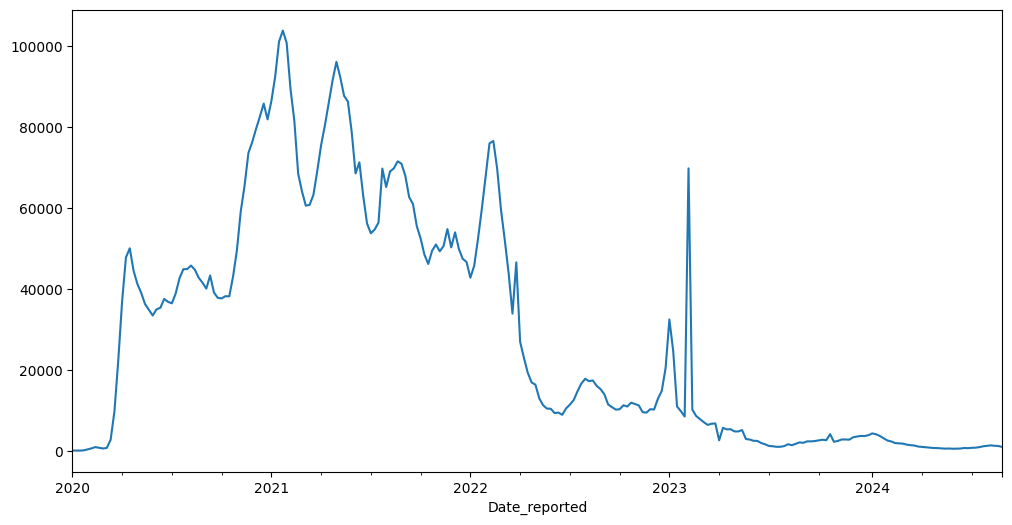

In [2]:
group = df.groupby("Date_reported")["New_deaths"].sum()
group.index.freq = "W"
print(group)
group.plot(figsize=(12,6))

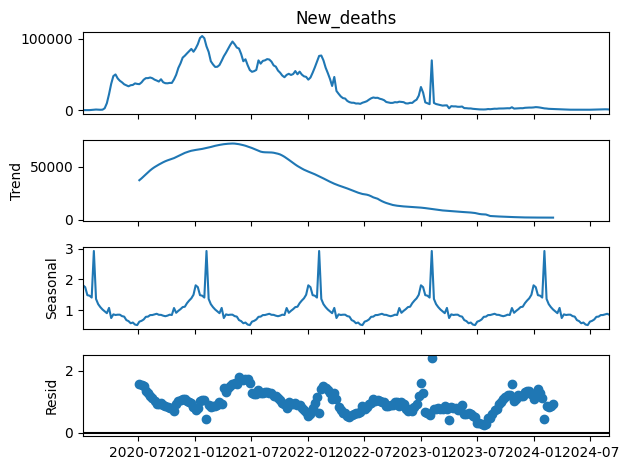

In [3]:
from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.pyplot as plt

seasonal = seasonal_decompose(group, model ='multiplicative') 
seasonal.plot()
plt.show()

In [4]:
train = group[0:122]
test = group[122:]

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=2399.011, Time=0.04 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=2431.778, Time=0.00 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=2408.697, Time=0.00 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=2418.655, Time=0.01 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=2429.855, Time=0.00 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=2399.079, Time=0.01 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=2404.575, Time=0.01 sec
 ARIMA(3,1,2)(0,0,0)[0] intercept   : AIC=2399.998, Time=0.02 sec
 ARIMA(2,1,3)(0,0,0)[0] intercept   : AIC=2398.369, Time=0.06 sec
 ARIMA(1,1,3)(0,0,0)[0] intercept   : AIC=2399.473, Time=0.02 sec
 ARIMA(3,1,3)(0,0,0)[0] intercept   : AIC=2402.802, Time=0.04 sec
 ARIMA(2,1,4)(0,0,0)[0] intercept   : AIC=2400.855, Time=0.04 sec
 ARIMA(1,1,4)(0,0,0)[0] intercept   : AIC=2400.772, Time=0.03 sec
 ARIMA(3,1,4)(0,0,0)[0] intercept   : AIC=2402.147, Time=0.04 sec
 ARIMA(2,1,3)(0,0,0)[0]          

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


<Axes: xlabel='Date_reported'>

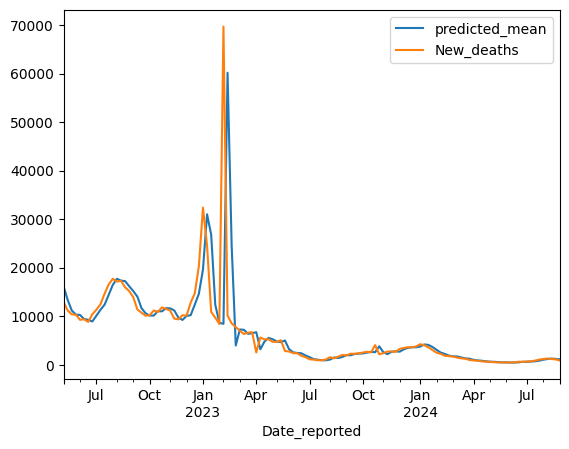

In [5]:
from pmdarima import auto_arima
from statsmodels.tsa.arima.model import ARIMA

stepwise_fit = auto_arima(train, 
                          trace=True, 
                          suppress_warnings=True, 
                          error_action="ignore", 
                          seasonal = True, 
                          stepwise = True)

p, d, q = stepwise_fit.order
P, D, Q, s = stepwise_fit.seasonal_order  # Musiman

model = ARIMA(group, order=(p, d, q))
model_fit = model.fit()

start = len(train) 
end = len(train) + len(test) - 1

predictions = model_fit.predict(start, end)

print(model_fit.summary())

predictions.plot(legend = True) 
test.plot(legend = True) 

<Axes: >

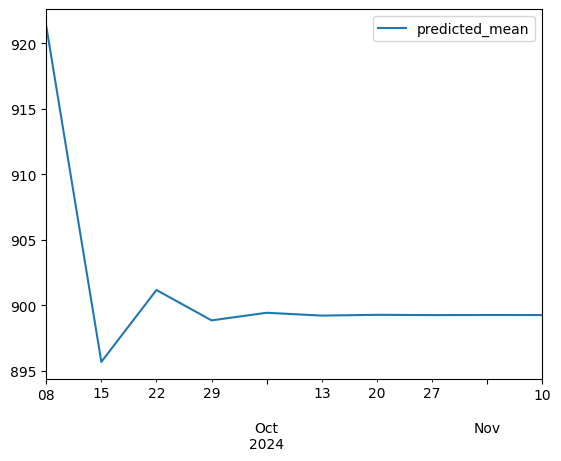

In [7]:
forecast = model_fit.forecast(10)
forecast.plot(legend = True)